# EDA: Ad click prediction (Sprint 4)
Imports `load_data`, `validate_schema`, `add_features` from `src/models.py`, so EDA and the pipeline use the same code.
Each finding has an id (F1...) and a **decision** that the pipeline follows. Descriptive EDA uses the full raw data;
nothing here is fit and reused by the pipeline.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import models as m
DATA = os.environ.get('AD_CLICK_DATA') or str(m.find_data(__import__('pathlib').Path(os.getcwd())))
df = m.load_data(DATA)
print(df.shape); df.head()

(1000, 8)
   user_age  gender device_type  time_of_day ad_placement_position ad_category  previous_clicks_on_similar_ads  clicked_ad
0     41.08  Female     Desktop        46.16                Footer      Gaming                         0.31400           0
1     43.11    Male      Mobile        29.78                Footer      Travel                         0.00277           0
2     44.96  Female     Desktop        32.70            In-content  E-commerce                         0.09840           0
3     39.74  Female      Mobile        58.37            In-content       Other                         0.07340           0
4     17.12    Male      Mobile        36.92            In-content      Gaming                         1.10000           0

## 1. Contract check against the brief (F1-F4)

In [2]:
q = m.validate_schema(df, need_target=True)
for k, v in q.items(): print(f'{k:45s} {v}')
print(); print(df.describe().T[['min','50%','max']].round(3))

n_rows                                        1000
age_outside_13_90                             11
time_of_day_outside_0_23                      537
previous_clicks_non_integer                   995
missing_feature_cells                         0
gender_levels_outside_brief                   []
device_type_levels_outside_brief              []
ad_placement_position_levels_outside_brief    ['footer', 'in-content', 'top-of-page']

                                 min     50%    max
user_age                        6.99  35.110  69.32
time_of_day                     8.45  24.345  99.59
previous_clicks_on_similar_ads  0.00   0.413  12.42
clicked_ad                      0.00   0.000   1.00


**F1** `time_of_day` runs 0-99.6 and 537/1000 rows exceed 23. It cannot be an hour. **Decision (user-confirmed):** keep as a plain numeric feature, unit unknown; no hour/evening features; the brief's "mobile evenings" interaction cannot be tested.
**F2** `ad_placement_position` levels are Top-of-page / In-content / Sidebar / Footer (brief: top / inline / sidebar). **Decision (default, UNCONFIRMED):** keep observed levels.
**F3** 11 rows have age < 13 (brief: 13-90). **Decision (default, UNCONFIRMED):** keep and flag; they are 1.1% of rows, and none of the 20 clicks can be traced to a data error, so removing rows is not justified without confirmation.
**F4** `previous_clicks_on_similar_ads` is fractional in 995/1000 rows (brief: integer count). Looks scaled or transformed upstream. **Decision:** treat as continuous.

## 2. Target (F5)

In [3]:
y = df['clicked_ad']
print(y.value_counts().to_dict(), f'rate = {y.mean():.3%}  (brief CTR range 0.5%-5%: inside)')
print('duplicates:', df.duplicated().sum())

{0: 980, 1: 20} rate = 2.000%  (brief CTR range 0.5%-5%: inside)
duplicates: 0


**F5** 20 clicks / 1000 rows (2%). A 75/25 split leaves **15 train and 5 test clicks**. PR-AUC floor = prevalence = 0.02; accuracy is meaningless (98% for "never click"). **Decision:** primary metric PR-AUC, with ROC-AUC, log-loss and Brier beside their floors; repeated stratified CV on train; test numbers carry a bootstrap CI and are labelled low-power.

## 3. Click rate by category (F6)

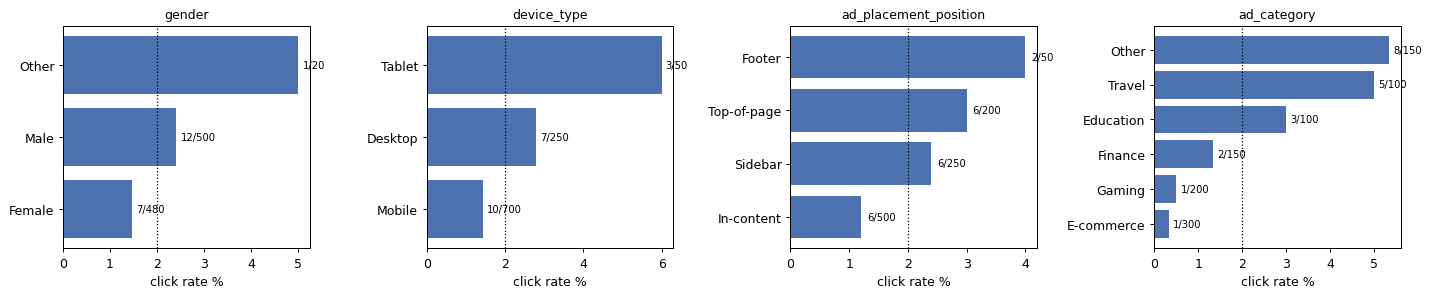

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a, c in zip(ax, ['gender','device_type','ad_placement_position','ad_category']):
    g = df.groupby(c)['clicked_ad'].agg(['mean','sum','count']).sort_values('mean')
    a.barh(g.index, g['mean']*100, color='#4c72b0')
    for i,(mn,s,n) in enumerate(zip(g['mean'],g['sum'],g['count'])): a.text(mn*100+.1, i, f'{int(s)}/{n}', va='center', fontsize=8)
    a.axvline(2, color='k', ls=':', lw=1); a.set_title(c, fontsize=10); a.set_xlabel('click rate %')
plt.tight_layout(); plt.show()

**F6** Every category cell holds 0-12 clicks (labels = clicks/impressions), so differences are mostly noise. Largest, with more than a handful of clicks: `ad_category` (Other 5.3% and Travel 5.0% vs E-commerce 0.3% and Gaming 0.5%). Placement: In-content 1.2% vs Top-of-page 3.0% is directionally the brief's "top beats inline" but rests on 6 clicks each. **Decision:** keep all categoricals (one-hot, unseen -> zeros); no per-level claims in the README.

## 4. Previous clicks (F7, the strongest and the contradictory signal)

                                 mean  sum  count
previous_clicks_on_similar_ads                   
(-0.00099646, 0.0548]           0.085   17    200
(0.0548, 0.254]                 0.015    3    200
(0.254, 0.648]                  0.000    0    200
(0.648, 1.55]                   0.000    0    201
(1.55, 12.42]                   0.000    0    199
spearman(prev_clicks, click) = -0.199


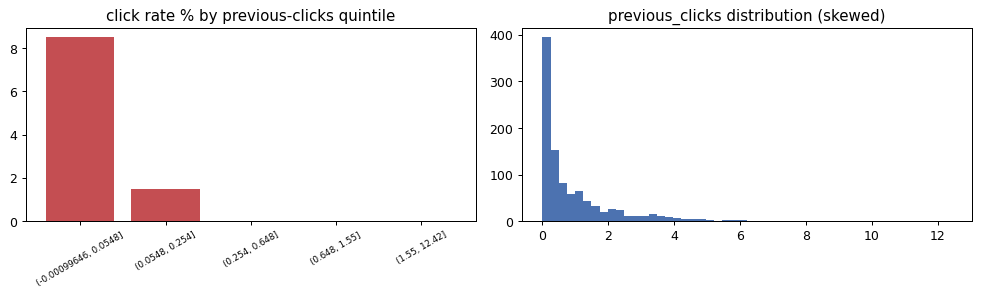

In [5]:
p = df['previous_clicks_on_similar_ads']
bins = pd.qcut(p, 5, duplicates='drop')
g = df.groupby(bins, observed=True)['clicked_ad'].agg(['mean','sum','count'])
print(g.round(4))
from scipy.stats import spearmanr
print('spearman(prev_clicks, click) =', round(spearmanr(p, y)[0], 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(range(len(g)), g['mean']*100, color='#c44e52'); ax[0].set_xticks(range(len(g))); ax[0].set_xticklabels([str(i) for i in g.index], rotation=30, fontsize=7)
ax[0].set_title('click rate % by previous-clicks quintile'); 
ax[1].hist(p, bins=50, color='#4c72b0'); ax[1].set_title('previous_clicks distribution (skewed)')
plt.tight_layout(); plt.show()

**F7** Opposite to the brief: 17 of 20 clicks are in the lowest quintile (rate 8.5%); zero clicks above 0.25. The column is right-skewed with most mass near 0-1.5. The effect is concentrated near zero (non-linear), which pre-registers the contrast: **tree models should beat the linear model.** **Decision (user-confirmed):** keep as-is, add stateless `log1p`, let models learn the direction, flag the contradiction in the README. If this column is inverted/rescaled upstream the direction is explained, but predictive use is unaffected.

## 5. Time of day, age (F8)

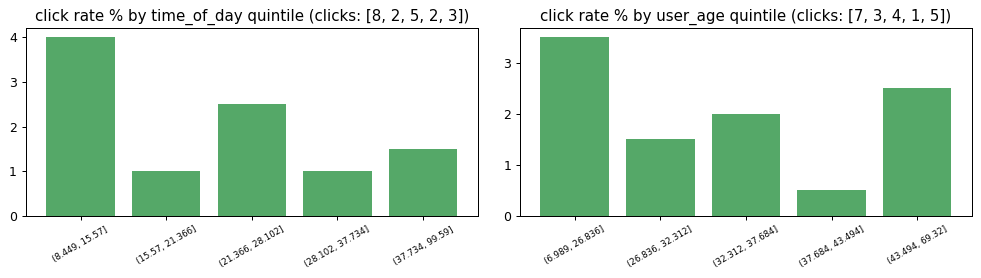

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, c in zip(ax, ['time_of_day','user_age']):
    gg = df.groupby(pd.qcut(df[c], 5, duplicates='drop'), observed=True)['clicked_ad'].agg(['mean','sum'])
    a.bar(range(len(gg)), gg['mean']*100, color='#55a868'); a.set_xticks(range(len(gg))); a.set_xticklabels([str(i) for i in gg.index], rotation=30, fontsize=7)
    a.set_title(f'click rate % by {c} quintile (clicks: {gg["sum"].astype(int).tolist()})')
plt.tight_layout(); plt.show()

**F8** No monotone pattern in `time_of_day` or `user_age` (2-8 clicks per bin). They stay as weak numeric features; no interaction engineering (the device x hour interaction in the brief needs a real hour).

## 6. Leak and quality scan (F9)

In [7]:
print('exact duplicate rows:', df.duplicated().sum(), '| duplicate feature rows with different label:', df.drop(columns='clicked_ad').duplicated(keep=False).sum() - df.duplicated(keep=False).sum())
print('missing cells:', int(df.isna().sum().sum()))
# does any single feature (nearly) determine the target?  purity of best category / best quintile
for c in ['gender','device_type','ad_placement_position','ad_category']:
    r = df.groupby(c)['clicked_ad'].mean(); print(f'{c:24s} max level rate {r.max():.3f}')

exact duplicate rows: 0 | duplicate feature rows with different label: 0
missing cells: 0
gender                   max level rate 0.050
device_type              max level rate 0.060
ad_placement_position    max level rate 0.040
ad_category              max level rate 0.053


**F9** No duplicates, no missing values, no single feature determines the target (max category click rate 6%). All seven features are plausibly known at serve time (user/device context, time, placement, category, history), so none is dropped for leakage. Caveat that data cannot verify: that `previous_clicks_on_similar_ads` counts only clicks **before** the impression (logged as an assumption).

## Findings -> decisions (summary)
| id | finding | decision |
|---|---|---|
| F1 | time_of_day not an hour | keep numeric, unit unknown (confirmed) |
| F2 | placement/gender levels differ from brief | keep observed levels (default) |
| F3 | 11 rows age < 13 | keep, flag (default) |
| F4 | previous clicks fractional | continuous |
| F5 | 2% positives, 20 clicks | PR-AUC primary, floors, repeated CV, CI on test |
| F6 | category cells tiny | keep, make no per-level claims |
| F7 | previous clicks inverse to brief, non-linear | keep, log1p, trees as contrast, flag caveat (confirmed) |
| F8 | no pattern in hour/age | weak features, no interactions |
| F9 | no leakage signals | keep all features, assumption logged |